## Partial Differential Equations

In a previous assignment, we have already considered the (elliptic, time-independent) Poisson equation
$$\nabla^2 u = f.$$

Here we'll consider two more kinds of PDEs, parabolic and hyperbolic, which introduce time dependence.

### 1D Heat Equation
The heat equation has the form
$$\frac{\partial u}{\partial t} = \alpha\frac{\partial^2 u}{\partial x^2}.$$

We assume that $x$ spans $[0, L]$ and that the initial condition $u|_{t=0} = u_0$ is given along with Dirichlet boundary conditions $u|_{x=0} = u_0(0), u|_{x=L} = u_0(L)$.

#### Method of Lines
Discretizing this equation along the spatial axis (letting $\mathbf{u}$ be the time-dependent vector of approximated $u$ values spaced at $\Delta x$ intervals on $[0, L]$) yields an ODE
$$\frac{d\mathbf{u}}{dt} = \frac{\alpha}{\Delta x^2} \mathbf{A} \mathbf{u},$$

with $\mathbf{A}$ being the tridiagonal $[-1, 2, -1]$ matrix representing the central discrete derivative.

Solving this ODE with an adaptive integrator constitutes the *method of lines*.

#### Forward-Time Central Space (FCTS) discretization
Using the discrete derivative along the time axis (which corresponds to forward Euler integration), we obtain

$$u_i^{n+1} = u_i^n + r \left(u_{i+1}^n - 2u_i^n + u_{i-1}^n\right), \quad r = \frac{\alpha \Delta t}{\Delta x^2}.$$

Analyzing the stability of this scheme (per von Neumann) relies on the fact that the right hand side expression is a linear operator in $\mathbf{u}^n$,
and thus the error, being the difference between the computed numerical solution and the exact algebraic solution for the scheme,
also satisfies these equations. Linearity also allows to perform Fourier analysis on the error and consider Fourier terms independently.
For the full derivation, see e.g. [here](https://en.wikipedia.org/wiki/Von_Neumann_stability_analysis#Illustration_of_the_method); it gives the stability condition
$$r \leq \frac12 \iff \Delta t \le \frac{\Delta x^2}{2\alpha}.$$

Doubling grid resolution ($N \to 2N$) requires 4 times as many time steps, causing computational cost to scale as $\mathcal{O}(N^3)$.

Below is a comparison of the $r = 0.49$ versus $r = 0.51$ regimes.

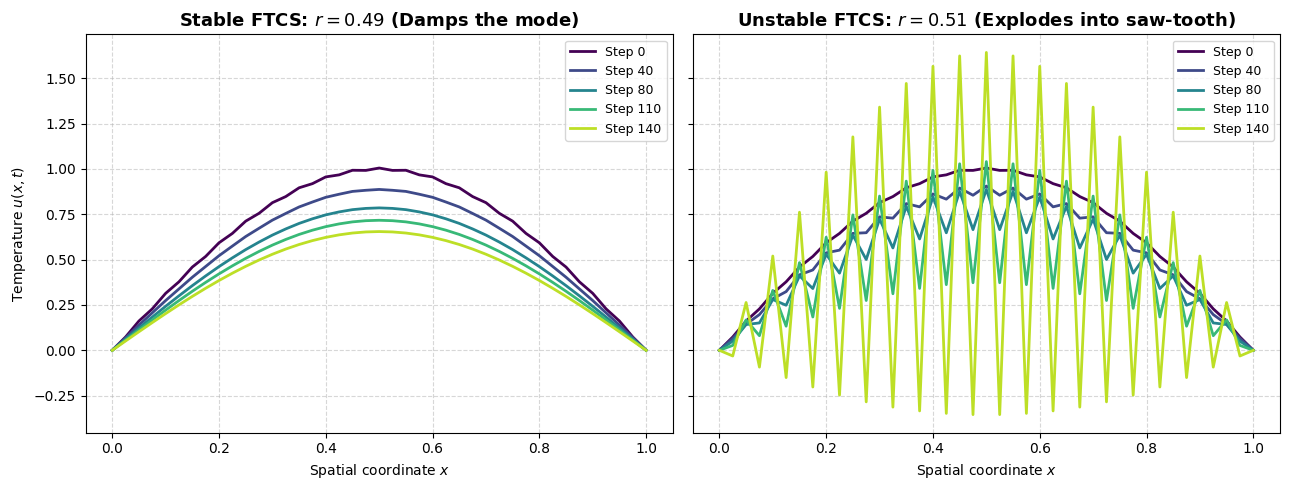

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# Domain parameters
L = 1.0
Nx = 41
x = np.linspace(0, L, Nx)
dx = x[1] - x[0]
alpha = 0.05

r_stable = 0.49
r_unstable = 0.51

dt_stable = r_stable * (dx**2) / alpha
dt_unstable = r_unstable * (dx**2) / alpha

# Directly seed the high-frequency Nyquist mode: (-1)^i with amplitude 0.005
nyquist_mode = 0.005 * ((-1) ** np.arange(Nx))
u_init = np.sin(np.pi * x) + nyquist_mode
u_init[0] = u_init[-1] = 0.0

def solve_ftcs(r, steps):
    u = u_init.copy()
    history = [u.copy()]
    for _ in range(steps):
        u[1:-1] = u[1:-1] + r * (u[2:] - 2.0 * u[1:-1] + u[:-2])
        u[0] = 0.0
        u[-1] = 0.0
        history.append(u.copy())
    return np.array(history)

steps = 140
hist_stable = solve_ftcs(r_stable, steps)
hist_unstable = solve_ftcs(r_unstable, steps)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
snapshots = [0, 40, 80, 110, 140]
colors = plt.cm.viridis(np.linspace(0, 0.9, len(snapshots)))

# Left: Stable r = 0.49 (smooths out the alternating ripple)
for step, col in zip(snapshots, colors):
    axes[0].plot(x, hist_stable[step], label=f"Step {step}", color=col, lw=2)

axes[0].set_title(r"Stable FTCS: $r = 0.49$ (Damps the mode)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Spatial coordinate $x$")
axes[0].set_ylabel("Temperature $u(x, t)$")
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend(loc="upper right", fontsize=9)

# Right: Unstable r = 0.51 (amplifies into visible zig-zag)
for step, col in zip(snapshots, colors):
    axes[1].plot(x, hist_unstable[step], label=f"Step {step}", color=col, lw=2)

axes[1].set_title(r"Unstable FTCS: $r = 0.51$ (Explodes into saw-tooth)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Spatial coordinate $x$")
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend(loc="upper right", fontsize=9)

plt.tight_layout()
plt.show()

### Implicit methods
* Backward Euler (BTCS): $$(\mathbf{I} - r\mathbf{A})\mathbf{u}^{n+1} = \mathbf{u}^n.$$ Unconditionally stable ($\vert{}G\vert{} < 1$ for all $\Delta t$). First-order in time $\mathcal{O}(\Delta t)$.
* Crank-Nicolson (Trapezoidal Rule): $$\left(\mathbf{I} - \frac{r}{2}\mathbf{A}\right)\mathbf{u}^{n+1} = \left(\mathbf{I} + \frac{r}{2}\mathbf{A}\right)\mathbf{u}^n.$$ Second-order in time $\mathcal{O}(\Delta t^2)$, unconditionally A-stable.
* At each time step, solving the linear system costs only $\mathcal{O}(N)$ using the [Thomas algorithm](https://en.wikipedia.org/wiki/Tridiagonal_matrix_algorithm) or `scipy.sparse.linalg.spsolve` because the matrix is tridiagonal.

Below is the demonstration of the methods on a benchmark task with a known analytical solution.

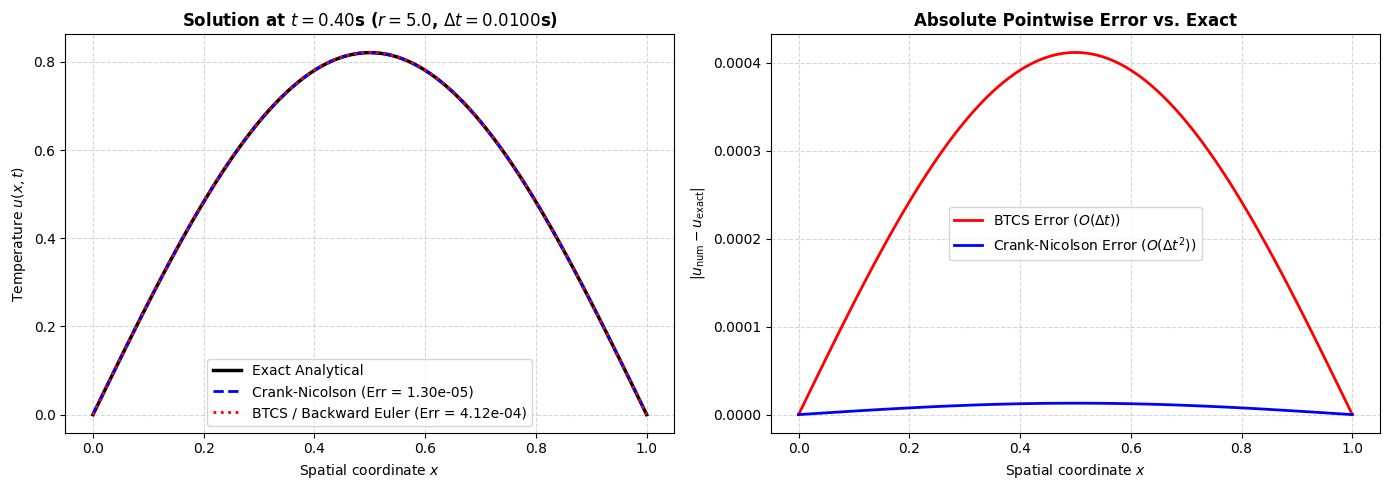

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import diags
from scipy.sparse.linalg import spsolve

# 1. Physical and domain parameters
L = 1.0                  # Domain length [0, L]
Nx = 101                 # Number of spatial points (dx = 0.01)
x = np.linspace(0, L, Nx)
dx = x[1] - x[0]
alpha = 0.05             # Diffusivity
t_final = 0.4            # Target time

# Run at r = 5.0 (10x larger than the FTCS stability threshold of 0.5)
r = 5.0
dt = r * (dx**2) / alpha
n_steps = int(round(t_final / dt))
t_actual = n_steps * dt

# Analytical benchmark: u(x, t) = exp(-alpha * pi^2 * t) * sin(pi * x)
u_exact = np.exp(-alpha * (np.pi**2) * t_actual) * np.sin(np.pi * x)

# Initial condition
u0 = np.sin(np.pi * x)

# 2. Interior grid setup (M = Nx - 2 interior unknowns)
M = Nx - 2
main_diag = np.ones(M)
off_diag = np.ones(M - 1)

# --- BTCS System: A_btcs * u^{n+1} = u^n ---
# A_btcs = tridiag(-r, 1 + 2r, -r)
A_btcs = diags(
    [-r * off_diag, (1.0 + 2.0 * r) * main_diag, -r * off_diag],
    [-1, 0, 1],
    format="csr"
)

# --- Crank-Nicolson System: A_cn * u^{n+1} = B_cn * u^n ---
# A_cn = tridiag(-r/2, 1 + r, -r/2)
# B_cn = tridiag( r/2, 1 - r,  r/2)
A_cn = diags(
    [-0.5 * r * off_diag, (1.0 + r) * main_diag, -0.5 * r * off_diag],
    [-1, 0, 1],
    format="csr"
)
B_cn = diags(
    [0.5 * r * off_diag, (1.0 - r) * main_diag, 0.5 * r * off_diag],
    [-1, 0, 1],
    format="csr"
)

# 3. Time stepping loops
u_btcs = u0.copy()
u_cn = u0.copy()

for _ in range(n_steps):
    # Solve for interior nodes: u_interior = A \ b
    u_btcs[1:-1] = spsolve(A_btcs, u_btcs[1:-1])
    u_cn[1:-1] = spsolve(A_cn, B_cn.dot(u_cn[1:-1]))

# 4. Compute infinity-norm errors
err_btcs = np.max(np.abs(u_btcs - u_exact))
err_cn = np.max(np.abs(u_cn - u_exact))

# 5. Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Solution profiles
ax1.plot(x, u_exact, 'k-', lw=2.5, label="Exact Analytical")
ax1.plot(x, u_cn, 'b--', lw=2.0, label=f"Crank-Nicolson (Err = {err_cn:.2e})")
ax1.plot(x, u_btcs, 'r:', lw=2.0, label=f"BTCS / Backward Euler (Err = {err_btcs:.2e})")
ax1.set_title(f"Solution at $t = {t_actual:.2f}$s ($r = {r}$, $\\Delta t = {dt:.4f}$s)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Spatial coordinate $x$")
ax1.set_ylabel("Temperature $u(x, t)$")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend()

# Pointwise error distribution
ax2.plot(x, np.abs(u_btcs - u_exact), 'r-', lw=2, label="BTCS Error ($O(\\Delta t)$)")
ax2.plot(x, np.abs(u_cn - u_exact), 'b-', lw=2, label="Crank-Nicolson Error ($O(\\Delta t^2)$)")
ax2.set_title("Absolute Pointwise Error vs. Exact", fontsize=12, fontweight='bold')
ax2.set_xlabel("Spatial coordinate $x$")
ax2.set_ylabel("$|u_{\\mathrm{num}} - u_{\\mathrm{exact}}|$")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()

### Linear Advection Equation

$$\frac{\partial u}{\partial t} + c \frac{\partial u}{\partial x} = 0.$$

#### Analytical solution
$$u(x, t) = u_0(x - ct)$$

can be obtained by introducing a change of variables $\xi = x - ct$, $\tau = t$ and substituting into the equation:

$$\frac{\partial u}{\partial \tau} - c\frac{\partial u}{\partial \xi} + c \frac{\partial u}{\partial \xi} = 0 \Rightarrow \frac{\partial u}{\partial \tau} = 0 \Rightarrow u = u_0(\xi).$$

#### FTCS attempt
Applying the centered difference

$$u_i^{n+1} = u_i^n - \frac{c \Delta t}{2\Delta x} (u_{i+1}^n - u_{i-1}^n)$$

is unconditionally unstable according to the von Neumann analysis (see also an alternative [truncation analysis](https://zingale.github.io/comp_astro_tutorial/advection_euler/advection/advection-partI.html#stability) leading to the same conclusion).

$C = \frac{c \Delta t}{\Delta x}$ is also called the Courant–Friedrichs–Lewy or CFL number.

#### Upwinding
For positive $c$, the information is flowing in the positive direction of $x$, and the physical insight is to use a finite difference reusing information from the information source:

$$u_i^{n+1} = u_i^n - C (u_i^n - u_{i-1}^n), \quad C = \frac{c \Delta t}{\Delta x}.$$

This method is stable for $C \leq 1$ (the CFL condition), which physically corresponds to having a characteristic line $x - ct$ crossing
the interval $[x_i, x_{i+1}]$ on which the following linear interpolation happens:

$$u_i^{n+1} = (1 - C) u_i^n + C u_{i-1}^n.$$

In the below demonstration, periodicity is used as a boundary condition, which is modeled by `np.roll`.

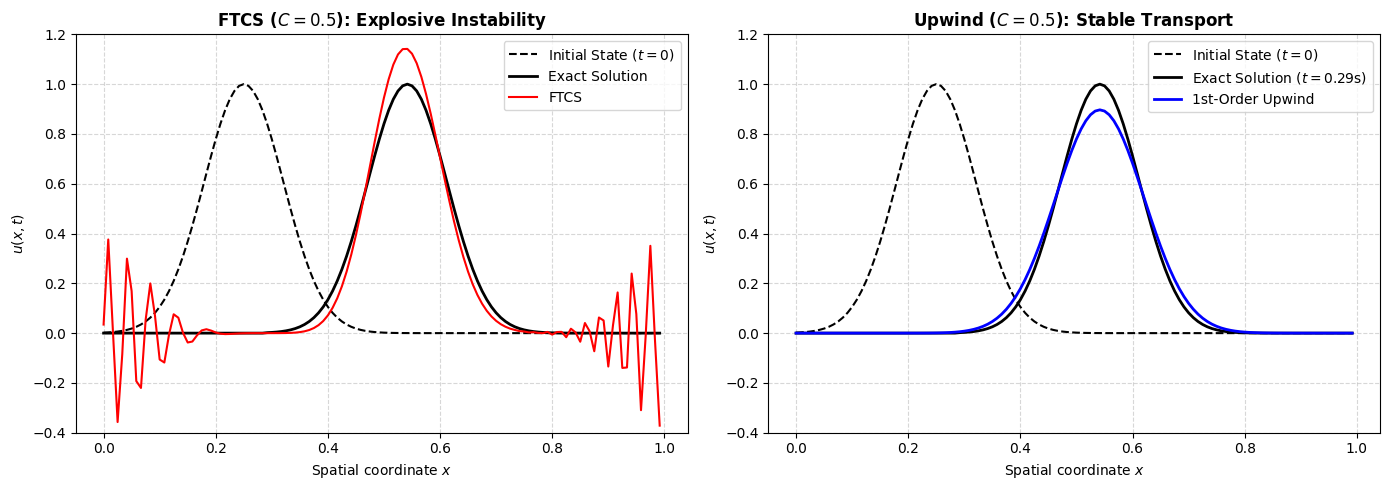

In [15]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Domain and physics parameters
L = 1.0                  # Domain [0, L]
Nx = 120                 # Spatial nodes
x = np.linspace(0, L, Nx, endpoint=False)
dx = x[1] - x[0]
c = 1.0                  # Wave speed (positive = rightward propagation)

# Courant number C = c * dt / dx (C <= 1 is stable for Upwind)
C = 0.5
dt = C * dx / c

# Initial condition: Smooth Gaussian pulse centered at x = 0.25
u0 = np.exp(-100.0 * (x - 0.25)**2)

# Number of time steps (t_final ≈ 0.35s, pulse should travel ~0.35 to the right)
n_steps = 70

# 2. Solvers with Periodic Boundary Conditions via np.roll
def run_ftcs(u_init, steps, courant):
    """Forward-Time Central-Space: u_i^{n+1} = u_i^n - (C/2) * (u_{i+1}^n - u_{i-1}^n)"""
    u = u_init.copy()
    for _ in range(steps):
        u_forward = np.roll(u, -1)   # u_{i+1}
        u_backward = np.roll(u, 1)   # u_{i-1}
        u = u - 0.5 * courant * (u_forward - u_backward)
    return u

def run_upwind(u_init, steps, courant):
    """1st-Order Upwind (c > 0): u_i^{n+1} = u_i^n - C * (u_i^n - u_{i-1}^n)"""
    u = u_init.copy()
    for _ in range(steps):
        u_backward = np.roll(u, 1)   # u_{i-1}
        u = u - courant * (u - u_backward)
    return u

# Run both schemes
u_ftcs = run_ftcs(u0, n_steps, C)
u_upwind = run_upwind(u0, n_steps, C)

# Analytical exact solution: u(x, t) = u0((x - c*t) mod L)
t_final = n_steps * dt
u_exact = np.exp(-100.0 * (((x - c * t_final) % L) - 0.25)**2)

# 3. Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: FTCS failure
ax1.plot(x, u0, 'k--', label="Initial State ($t = 0$)")
ax1.plot(x, u_exact, 'k-', lw=2, label="Exact Solution")
ax1.plot(x, u_ftcs, 'r-', lw=1.5, label="FTCS")
ax1.set_title(f"FTCS ($C = {C}$): Explosive Instability", fontsize=12, fontweight='bold')
ax1.set_xlabel("Spatial coordinate $x$")
ax1.set_ylabel("$u(x, t)$")
ax1.set_ylim(-0.4, 1.2)
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend()

# Right: Upwind success
ax2.plot(x, u0, 'k--', label="Initial State ($t = 0$)")
ax2.plot(x, u_exact, 'k-', lw=2, label=f"Exact Solution ($t = {t_final:.2f}$s)")
ax2.plot(x, u_upwind, 'b-', lw=2, label="1st-Order Upwind")
ax2.set_title(f"Upwind ($C = {C}$): Stable Transport", fontsize=12, fontweight='bold')
ax2.set_xlabel("Spatial coordinate $x$")
ax2.set_ylabel("$u(x, t)$")
ax2.set_ylim(-0.4, 1.2)
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()

**BONUS**: Explain why the peak of the transported wave diminished over time in the Upwind scheme.